In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from eo_toolkit import (
    load_cached_sentinel1_as_numpy_tensor,
    correlated_seasonal_mann_kendall,
    compute_monthly_median,
    compute_patch_series,
)

In [3]:
sentinel1_data = load_cached_sentinel1_as_numpy_tensor(Path("data/sentinel1_lat_48.83_lon_7.85_size_3000"))

In [4]:
s1_vv_vh_bands = sentinel1_data["bands"]  # (time, bands, depth, width), e.g., (482, 2, 103, 103)
dates = sentinel1_data["dates"]           # (time, )
orbits = sentinel1_data["orbits"]         # (time, )

In [5]:
df = compute_patch_series(s1_vv_vh_bands, dates)

In [6]:
def plot_time_series(s, title="Sentinel-1 Time Series", ylabel="Value"):    
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(s.index, s.values, marker="o", linestyle="-", markersize=3, color="tab:blue", alpha=0.8)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("Date", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


--- vh_db ---
  trend: increasing
  p: 0.049
  sen_slope_per_year: 0.040
  n_months: 130


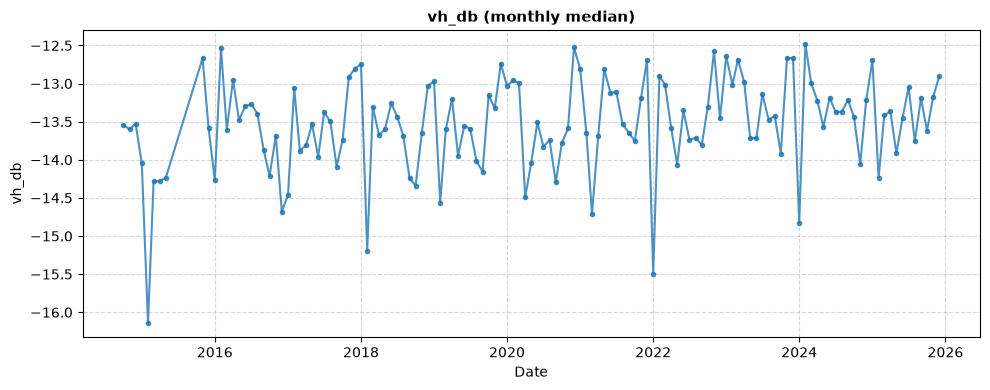


--- vv_db ---
  trend: no trend
  p: 0.058
  sen_slope_per_year: 0.022
  n_months: 130


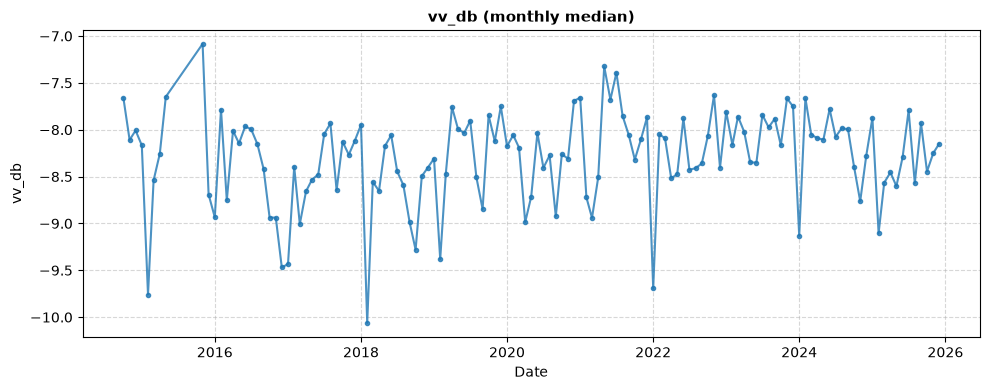


--- ratio_db ---
  trend: no trend
  p: 0.852
  sen_slope_per_year: 0.009
  n_months: 130


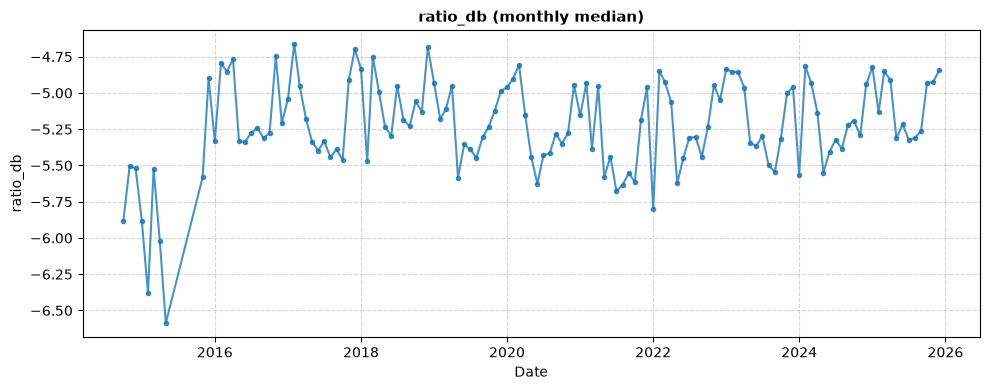


--- rvi ---
  trend: no trend
  p: 0.852
  sen_slope_per_year: 0.001
  n_months: 130


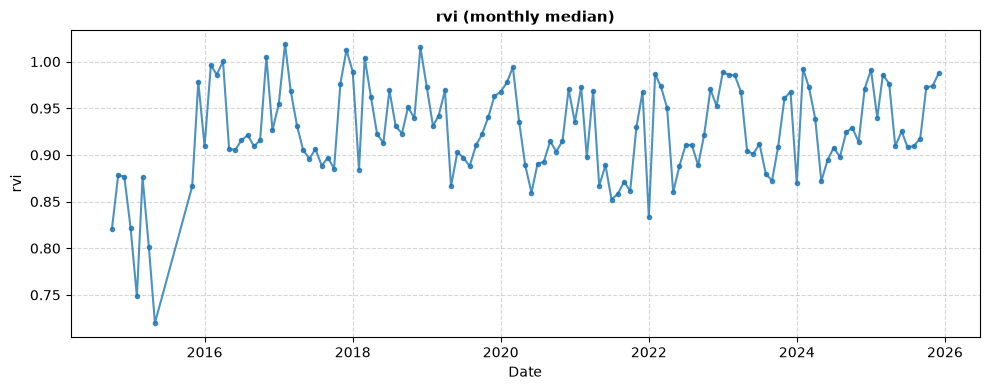

In [9]:
for col in ("vh_db", "vv_db", "ratio_db", "rvi"):
    s = compute_monthly_median(df, col)
    res = correlated_seasonal_mann_kendall(s)
    
    print(f"\n--- {col} ---")
    for key, val in res.items():
        if isinstance(val, float):
            print(f"  {key}: {val:.3f}")
        else:
            print(f"  {key}: {val}")
            
    plot_time_series(s, title=f"{col} (monthly median)", ylabel=col)